In [116]:
import pandas as pd

In [117]:
df = pd.read_csv('/kaggle/input/competitions/mlp-sept-2026-ka-1/train.csv')

### 1. <font size="4">Identifying data types of different columns<font>

In [118]:
# it will tell us about data types of different columns present in the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           40000 non-null  int64  
 1   airline      35387 non-null  object 
 2   flight       40000 non-null  object 
 3   source       40000 non-null  object 
 4   departure    35208 non-null  object 
 5   stops        37681 non-null  object 
 6   arrival      40000 non-null  object 
 7   destination  40000 non-null  object 
 8   class        40000 non-null  object 
 9   duration     36987 non-null  float64
 10  days_left    35562 non-null  float64
 11  price        40000 non-null  int64  
dtypes: float64(2), int64(2), object(8)
memory usage: 3.7+ MB


### 2. <font size="4">Descriptive Statistics of numerical columns </font>

In [119]:
# it will tell us about descriptive stats of different 
# numerical columns present in our dataset

df.describe()

,id,duration,days_left,price
count,40000.00000,36987.000000,35562.000000,40000.00000
mean,19999.50000,12.004088,26.197936,20801.49025
std,11547.14972,7.108063,13.469232,22729.14842
min,0.00000,0.830000,1.000000,1105.00000
25%,9999.75000,6.670000,15.000000,4687.00000
50%,19999.50000,11.080000,26.000000,7353.00000
75%,29999.25000,15.920000,38.000000,42521.00000
max,39999.00000,47.080000,49.000000,114704.00000


### 3. <font size="4"> Identifying and handeling duplicates </font>

In [120]:
# we have to remove duplicates before we split the data into train set and val set 

print(df.duplicated(subset = df.columns.difference(['id'])).sum())

250


In [121]:
# we have 250 duplicates lets remove them 

df = df.drop_duplicates(subset = df.columns.difference(['id']))

### 4. <font size="4">Diving data into training data and validation</font>

In [122]:
from sklearn.model_selection import train_test_split 

y = df['price']
x = df.drop(columns = ['price'])


x_train , x_val , y_train , y_val = train_test_split(x , y , test_size = 0.20 , random_state = 42)


In [123]:
print(x_train.shape)
print(y_train.shape)

(31800, 11)
(31800,)


### 5. <font size="4"> Identifying and handeling missing values </font>

In [124]:
# identification and handeling of the missing values present in the dataset 

x_train.isna().sum()

id                0
airline        3645
flight            0
source            0
departure      3809
stops          1822
arrival           0
destination       0
class             0
duration       2380
days_left      3368
dtype: int64

In [125]:
# to determine the strategy for imputer for our missing values lets first find the 
# unique categories in categorical columns 

categorical_columns_missing = ['airline' , 'departure' , 'stops']
numerical_columns_missing = ['duration' , 'days_left']

### STRATEGY FOR CATEGORICAL COLUMNS

In [126]:
for col in categorical_columns_missing:

    print(f"Column name is {col}")
    print(f"num unique values : {x_train[col].nunique()} ")
    print(f"unique features are : {x_train[col].unique()}")

Column name is airline
num unique values : 6 
unique features are : ['Vistara' 'AirAsia' 'Indigo' 'GO_FIRST' 'Air_India' 'SpiceJet' nan]
Column name is departure
num unique values : 6 
unique features are : ['Evening' 'Morning' nan 'Early_Morning' 'Afternoon' 'Night' 'Late_Night']
Column name is stops
num unique values : 3 
unique features are : [nan 'one' 'zero' 'two_or_more']


In [127]:
# if our data has few missing features like %5 or less we can simply use most_frequent 
# on our imputer otherwise if there are many missing we should use replace by 
# constant strategy

#lets find this

for col in categorical_columns_missing:

    print(f"Value count for {col}\n")
    print(x_train[col].value_counts(dropna= False))
    print("\n")
    print("Percentage of NAN : \n")
    print((x_train[col].isna().sum() / len(x_train[col]) )* 100)

Value count for airline

airline
Vistara      11873
Air_India     7359
Indigo        4188
NaN           3645
GO_FIRST      2278
AirAsia       1561
SpiceJet       896
Name: count, dtype: int64


Percentage of NAN : 

11.462264150943396
Value count for departure

departure
Morning          6583
Early_Morning    6182
Evening          6146
Night            4505
Afternoon        4455
NaN              3809
Late_Night        120
Name: count, dtype: int64


Percentage of NAN : 

11.977987421383649
Value count for stops

stops
one            25043
zero            3744
NaN             1822
two_or_more     1191
Name: count, dtype: int64


Percentage of NAN : 

5.729559748427673



<font size="4">
from the percentage we got we can conclude that 

airline -> Strategy = constatn = "unknown"
#departure -> Strategy = constant = "unknown"

SINCE STOP COLUMN IS ORDINAL WE CANNOT SIMPLY USE CONSTANT STRATEGY SO WE WILL 
USE MOST FREQUENT

to implement tehse we can make a pipeline since we will have to implement it on x_val a
on x_train too in future 
</font>


### STRATEGY FOR NUMERICAL COLS

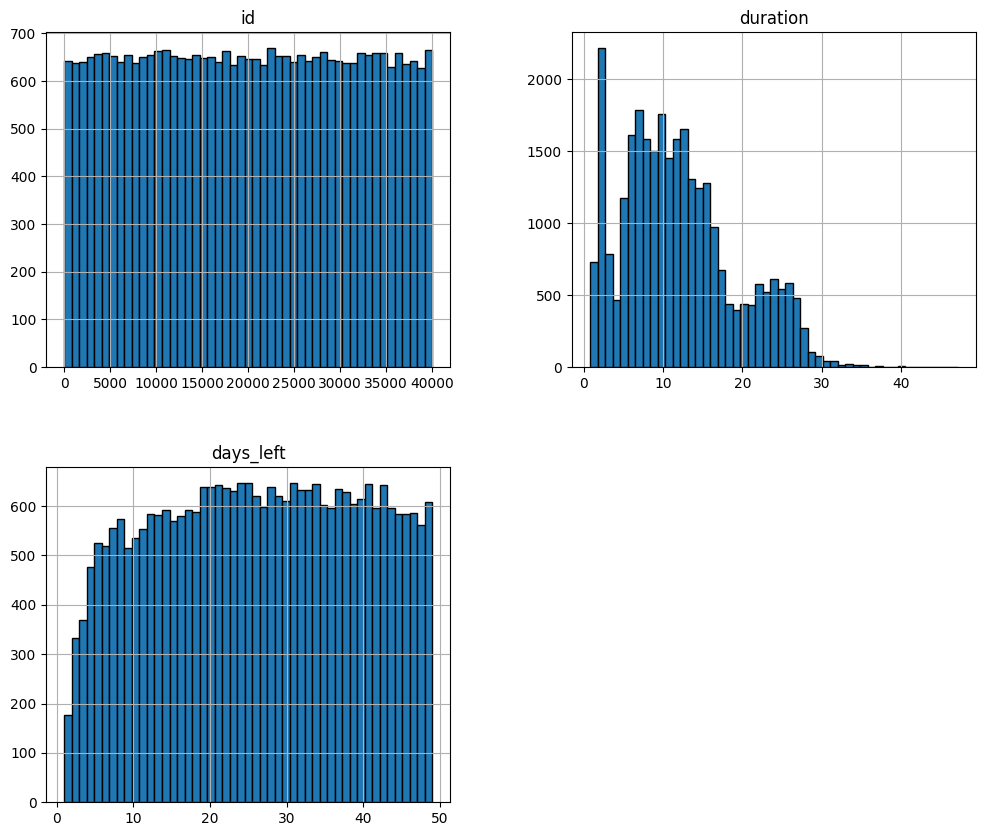

In [128]:
# lets first plot a histogram for each numerical feature , we can ignore id here

import matplotlib.pyplot as plt

x_train.hist(figsize=(12, 10) , edgecolor = "black" , bins=49)
plt.show()

In [129]:
# by analyzing our histogram we can conclude that if the histogram is symmetric we can
# use mean as an appropriate replacement strategy otherwise we can use median

# lets also print the median , mean and .skew() to further confirm our idea

for col in numerical_columns_missing:

    print(f"Percentage of NAN for {col}: \n")
    print(f"{ (x_train[col].isna().sum() / len(x_train[col])) * 100} \n")
    print(f" MEDIAN : {x_train[col].median()} \n")
    print(f" MEAN : { x_train[col].mean()} \n")
    print(f" SKEW : { x_train[col].skew()} \n")
    
    


Percentage of NAN for duration: 

7.484276729559748 

 MEDIAN : 11.0 

 MEAN : 11.970127124405167 

 SKEW : 0.6195200584324722 

Percentage of NAN for days_left: 

10.59119496855346 

 MEDIAN : 26.0 

 MEAN : 26.18633933595948 

 SKEW : -0.05036092110469646 



In [130]:
# duration column is medium right skewed and its mean and median differ from each other too confirming 
# our idea of using median 
# the days left column has little to no skew its roughtly symmetric its median and mean are similar to 
# each other too hence we will use mean as imputation method for it


<font size="4">
FINAL IMPUATION METHODS DECIDED : 

airline -> Strategy = constatn = "unknown"
departure -> Strategy = constant = "unknown"
stops -> strategy = most_frequent 
duraiion -> strategy = median 
days_left -> strategy = mean 
</font>


### 5. <font size="4">Feature Engineering</font>

In [131]:
# FEATURE ENGINEERING

def flight_prefix(df):
    return df["flight"].str.split("-").str[0]

known = x_train["airline"].notna()

print(pd.crosstab(flight_prefix(x_train)[known], x_train.loc[known, "airline"]))

prefix_to_airline = (
    pd.DataFrame({"prefix": flight_prefix(x_train)[known],
                  "airline": x_train.loc[known, "airline"]})
      .groupby("prefix")["airline"]
      .agg(lambda s: s.mode()[0])
)
print(prefix_to_airline)


def fill_airline(df):
    df = df.copy()
    df["airline"] = df["airline"].fillna(flight_prefix(df).map(prefix_to_airline))
    return df

print("airline missing before:", x_train["airline"].isna().sum())
x_train = fill_airline(x_train)
x_val   = fill_airline(x_val)
print("airline missing after: ", x_train["airline"].isna().sum())

airline   AirAsia  Air_India  GO_FIRST  Indigo  SpiceJet  Vistara
flight                                                           
0.00E           0          0         0      17         0        0
0.00E+00        0          0         0    3716         0        0
6.00E           0          0         0     455         0        0
AI              0       7359         0       0         0        0
G8              0          0      2278       0         0        0
I5           1561          0         0       0         0        0
SG              0          0         0       0       896        0
UK              0          0         0       0         0    11873
prefix
0.00E          Indigo
0.00E+00       Indigo
6.00E          Indigo
AI          Air_India
G8           GO_FIRST
I5            AirAsia
SG           SpiceJet
UK            Vistara
Name: airline, dtype: object
airline missing before: 3645
airline missing after:  0


### 6. <font size="4"> Outlier detection in numerical columns using IQR</font>



In [132]:
numerical_cols_except_id = ['duration' , 'days_left']

for col in numerical_cols_except_id:

    q1 = x_train[col].quantile(0.25)
    q3 = x_train[col].quantile(0.75)

    iqr = q3 - q1 

    lower_bound = q1 - iqr * 1.5
    upper_bound = q3 + iqr * 1.5

    outliers = ( ( x_train[col] < lower_bound ) | ( x_train[col] > upper_bound ) ).sum()

    print(f"FOR COL {col} : ")
    print(f" lower_bound : {lower_bound} \n upper_bound : {upper_bound} \n percentage outliers is { (outliers/ len(x_train[col])) * 100}")
    
    print(f" Num Outliers in {col} are {outliers} \n")

FOR COL duration : 
 lower_bound : -7.205 
 upper_bound : 29.795 
 percentage outliers is 0.6163522012578616
 Num Outliers in duration are 196 

FOR COL days_left : 
 lower_bound : -19.5 
 upper_bound : 72.5 
 percentage outliers is 0.0
 Num Outliers in days_left are 0 



In [133]:
# the outliers for duration cols are only 0.6% of the entire datasets so dropping them 
# wont create a big difference but instead will teach the model that there can never be 
# long flights hence we wont drop them

In [134]:
# ALSO FIND  OUTLIERS IF THERE ARE IN y_train aka price column 

q1 = y_train.quantile(0.25)
q3 = y_train.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - iqr * 1.5
upper_bound = q3 + iqr * 1.5

outliers = ( ( y_train < lower_bound ) | ( y_train > upper_bound ) ).sum()

print(f" lower_bound : {lower_bound} \n upper_bound : {upper_bound} \n percentage outliers is { (outliers/ len(y_train)) * 100}")

print(f" Num Outliers  are {outliers} \n")

 lower_bound : -51959.25 
 upper_bound : 99106.75 
 percentage outliers is 0.018867924528301886
 Num Outliers  are 6 



In [135]:
# price has only 6 outliers these are maybe expensive flights so cost more they constitute 0.02 % of the data so 
# dropping them wont really affect the model that much hence i will keep them , they are likey real values

price has only 5 outliers these are maybe expensive flights so cost more they constitute 0.01 % of the data so 
dropping them wont really affect the model that much hence i will keep them 

### 6. <font size="4">Visualization</font>

In [136]:
# VISUALIZATION
import seaborn as sns 

### histogram : 

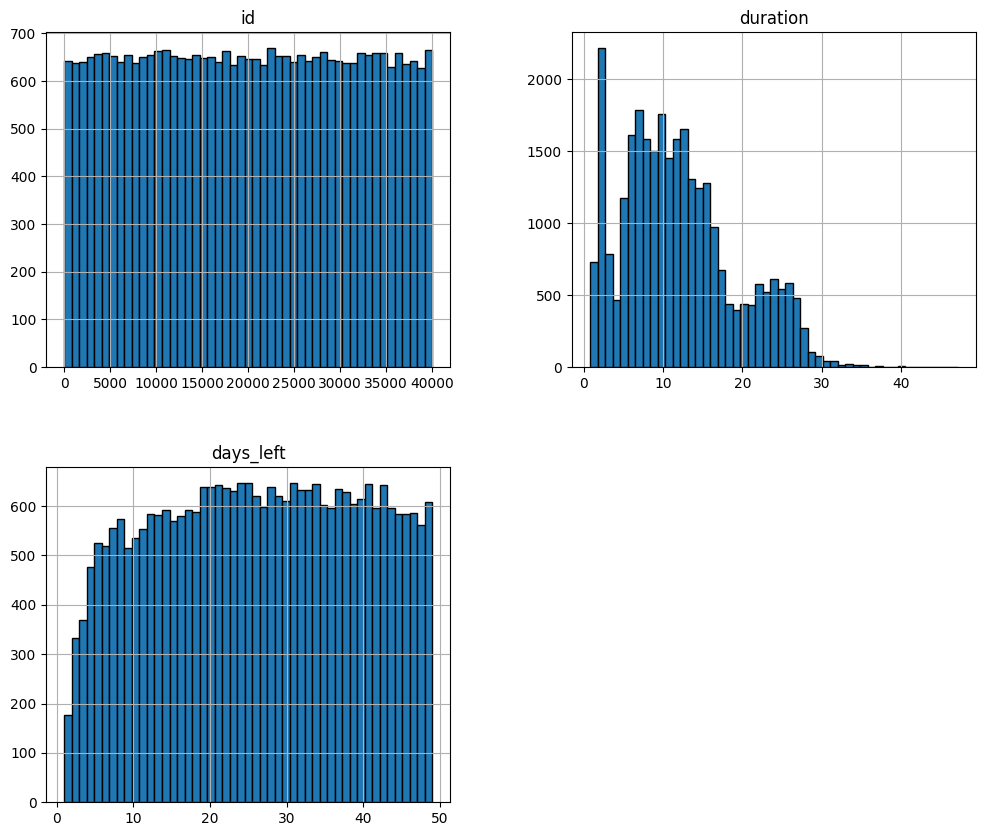

In [137]:
x_train.hist(figsize=(12, 10) , edgecolor = "black" , bins=49)
plt.show()

we can see that here days_left appears to be symmetric and duration appears to be right skewed 
which means that its median is likely smaller than its mean 

### BOXPLOT 

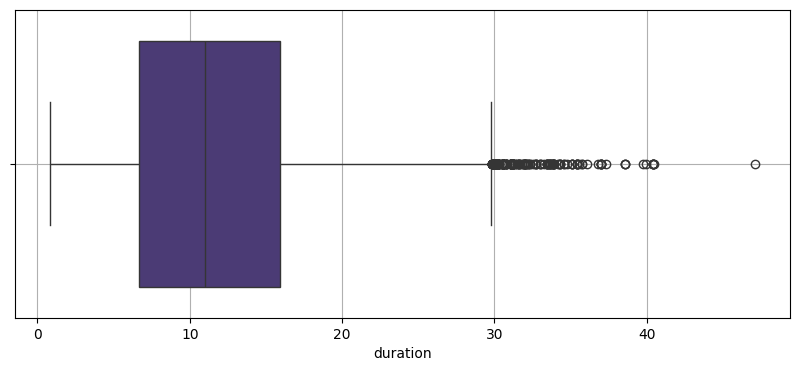

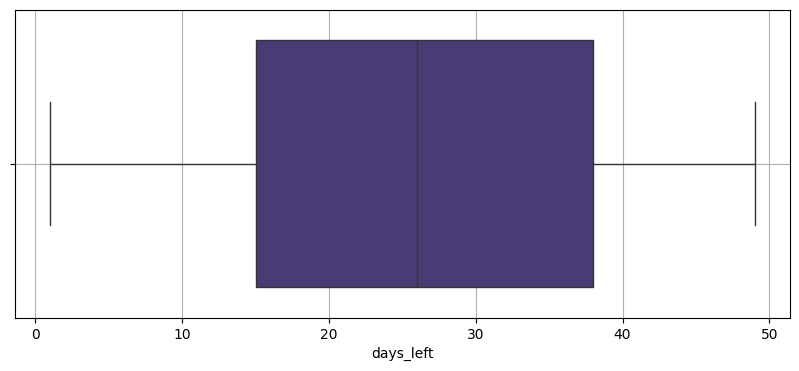

In [138]:
for col in numerical_cols_except_id:
    plt.figure(figsize=(10 , 4))
    sns.boxplot(data = x_train , x = col , color = sns.color_palette("viridis")[0])
    plt.grid()
    plt.show()

 the boxplot confirms that there are some values present outside iqr range for duration column
 but none present for the days_left column

### class boxplot 

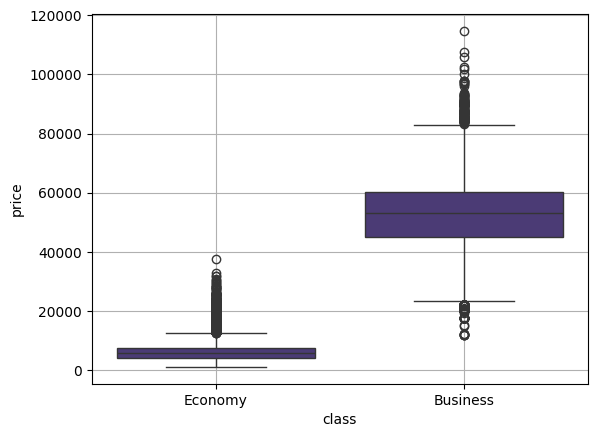

In [139]:
train_df = x_train.assign(price = y_train)
sns.boxplot(data = train_df , x = "class" , y= "price" , color = sns.color_palette("viridis")[0])
plt.grid()
plt.show()

the above chart gives us idea of price vs class and also about where the outliers are 
taking place and in which class and are they extreme 
this confirms that these are not extreme outliers as for economy maybe the users got 
some price hike due to festivals and for business maybe they got some disocount or 
some price hike on festival

### 7. <font size="4">Scale numerical and encode categorical features</font>

| Column | Type | Group | Imputer | Transformation |
| :--- | :--- | :--- | :--- | :--- |
| `id` | identifier | drop | — | — |
| `airline` | nominal | keep | constant `"Unknown"` | OneHotEncoder |
| `flight` | nominal | drop | — | — |
| `source` | nominal | keep | — | OneHotEncoder |
| `departure` | nominal | keep | constant `"Unknown"` | OneHotEncoder |
| `stops` | ordinal | keep | most_frequent | OrdinalEncoder (order: `['zero', 'one', 'two_or_more']`) |
| `arrival` | nominal | keep | — | OneHotEncoder |
| `destination` | nominal | keep | — | OneHotEncoder |
| `class` | nominal | keep | — | OneHotEncoder |
| `duration` | numerical | keep | median | StandardScaler |
| `days_left` | numerical | keep | mean | StandardScaler |

In [140]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer 
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler , OneHotEncoder , OrdinalEncoder

In [141]:
median_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)

mean_pipeline = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler()
)


nominal_pipeline = make_pipeline(
    SimpleImputer(strategy='constant' , fill_value = 'Unknown'),
    OneHotEncoder(handle_unknown = "ignore" , sparse_output=False)
)

ordinal_pipeline = make_pipeline(
    SimpleImputer(strategy = 'most_frequent'),
    OrdinalEncoder(categories = [['zero' , 'one' , 'two_or_more']])
)


In [142]:
preprocessor = ColumnTransformer([
    ("num_median" , median_pipeline , ['duration']),
    ("num_mean" , mean_pipeline , ['days_left']),
    ("nominal" , nominal_pipeline , ['airline', 'source', 'departure', 'arrival', 'destination', 'class']),
    ("ordinal" , ordinal_pipeline , ['stops'])
])

In [143]:
x_train_transformed = preprocessor.fit_transform(x_train)

In [144]:
print(x_train_transformed.shape)

(31800, 36)


### 8. <font size="4">Model Building</font> 

In [145]:
from sklearn.linear_model import LinearRegression , Ridge , Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor , GradientBoostingRegressor , HistGradientBoostingRegressor
from sklearn.metrics import r2_score

### 8 models built

In [146]:
models = {
    "Linear Regression" : LinearRegression(),
    "Ridge Regression" : Ridge(),
    "Lasso Regression" : Lasso(),
    "KNN" : KNeighborsRegressor(n_jobs = -1),
    "Decision Tree" : DecisionTreeRegressor(random_state = 42),
    "Random Forest" : RandomForestRegressor(random_state = 42 , n_jobs = -1),
    "Gradient Boost" : GradientBoostingRegressor(random_state = 42),
    "Hist Gradient Boost" : HistGradientBoostingRegressor(random_state = 42)
}

In [ ]:
results = []

for name , model in models.items():

    pipeline = make_pipeline(preprocessor , model)
    pipeline.fit(x_train , y_train)

    train_r2 = r2_score(y_train , pipeline.predict(x_train))
    val_r2 = r2_score(y_val , pipeline.predict(x_val))

    results.append({
        "model" : name,
        "train_r2" : train_r2,
        "val_r2" : val_r2
    })

    print(name , "done")

results_df = pd.DataFrame(results).sort_values("val_r2" , ascending=False)

results_df
    

Linear Regression done


### 9. <font size="4">Hyper Parameter tuning</font>

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

rf_pipe = make_pipeline(
    preprocessor,
    RandomForestRegressor(random_state=42)
)

rf_params = {
    "randomforestregressor__n_estimators" : [ 100 , 200 , 300],
    "randomforestregressor__max_depth" : [None , 20 , 30],
    "randomforestregressor__min_samples_leaf" : [1 , 2 , 4],
    "randomforestregressor__max_features" : [1.0 , 0.5 , "sqrt"]
}

rf_search = RandomizedSearchCV(
    rf_pipe , rf_params, n_iter = 10 , cv = 3 , scoring="r2" , random_state = 42 , n_jobs = -1 , verbose=3
)


rf_search.fit(x_train , y_train)


In [ ]:
print(rf_search.best_params_)
print("best CV r2:", rf_search.best_score_)
print("val r2:", r2_score(y_val, rf_search.predict(x_val)))

In [ ]:
hg_pipeline = make_pipeline(
    preprocessor,
    HistGradientBoostingRegressor(random_state = 42)
)


hg_params = {
    "histgradientboostingregressor__learning_rate" : [0.03 , 0.05 , 0.1 , 0.2],
    "histgradientboostingregressor__max_iter" : [200 , 500 , 1000],
    "histgradientboostingregressor__max_leaf_nodes" : [ 31 , 63 , 127],
    "histgradientboostingregressor__min_samples_leaf" : [10 , 20 ,50]
}

hg_search = RandomizedSearchCV(
    hg_pipeline , hg_params, n_iter = 10 , cv = 3 , scoring="r2" , random_state = 42 , n_jobs = -1 , verbose=3 
)

hg_search.fit(x_train , y_train)

In [ ]:
print(hg_search.best_params_)
print("best CV r2:", hg_search.best_score_)
print("val r2:", r2_score(y_val, hg_search.predict(x_val)))

In [ ]:
gb_pipeline = make_pipeline(
    preprocessor,
    GradientBoostingRegressor(random_state = 42)
    
)

gb_params = {
    "gradientboostingregressor__n_estimators" : [100 , 200 , 300],
    "gradientboostingregressor__learning_rate" : [0.05 , 0.1 , 0.2],
    "gradientboostingregressor__max_depth" : [3 , 5 , 7],
    "gradientboostingregressor__subsample" : [0.8 , 1.0]
}

gb_search = RandomizedSearchCV(
    gb_pipeline , gb_params, n_iter = 10 , cv = 3 , scoring="r2" , random_state = 42 , n_jobs = -1 , verbose=3 
)

gb_search.fit(x_train , y_train)

In [ ]:
print(gb_search.best_params_)
print("best CV r2:", gb_search.best_score_)
print("val r2:", r2_score(y_val, gb_search.predict(x_val)))

### 10. <font size="4">Final Model Comparison</font>

In [ ]:
tuned_models = {
    "Random Forest (tuned)":       rf_search.best_estimator_,
    "Hist Gradient Boost (tuned)": hg_search.best_estimator_,
    "Gradient Boost (tuned)":      gb_search.best_estimator_,
}

tuned_results = []
for name, model in tuned_models.items():
    tuned_results.append({
        "model": name,
        "train_r2": r2_score(y_train, model.predict(x_train)),
        "val_r2":   r2_score(y_val,   model.predict(x_val)),
    })

comparison_df = (pd.concat([results_df, pd.DataFrame(tuned_results)], ignore_index=True)
                   .sort_values("val_r2", ascending=False)
                   .reset_index(drop=True))
comparison_df["gap"] = comparison_df["train_r2"] - comparison_df["val_r2"]
comparison_df

### 11. <font size="4">Submission on test dataset</font>

In [ ]:
x_test = pd.read_csv("/kaggle/input/competitions/mlp-sept-2026-ka-1/test.csv")

x_test = fill_airline(x_test)


print(x_test.shape)

In [ ]:
test_pred = rf_search.predict(x_test)


submission = pd.DataFrame({
    "id" : x_test['id'],
    "price" : test_pred
})

submission.to_csv("submission.csv" , index=False)

print(submission.shape)
print(submission.head(3))